# XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN CUSTOMER CHURN

## 1. Giới thiệu và phạm vi thực nghiệm

Notebook xây dựng và so sánh ba mô hình dự đoán khách hàng rời bỏ dịch vụ (Customer Churn): KNN, Decision Tree và Gaussian Naive Bayes.

Quy trình: kiểm tra dữ liệu → huấn luyện baseline → tuning siêu tham số → cross-validation/OOF → đánh giá test → phân tích lỗi, feature importance và Risk × Value.

Môi trường chạy: Python 3.12.0, scikit-learn 1.7.2, NumPy 1.26.4, pandas 2.2.3, SciPy 1.11.4, statsmodels 0.14.4, joblib 1.5.2. Phiên bản dependencies được ghi trong `requirements.txt` ở gốc repository.

## 2. Imports và cấu hình

In [1]:
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[variable] = "1"
# Xử lý dữ liệu
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

# Trực quan hóa
import matplotlib.pyplot as plt

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Model selection
from sklearn.model_selection import (
    StratifiedKFold, 
    cross_validate,
    GridSearchCV,
    train_test_split,
    cross_val_predict
)

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from IPython.display import display

from sklearn.base import clone # 
from sklearn.pipeline import Pipeline # 

# Cố định BLAS threads để khoảng cách KNN tái lập giữa các tiến trình.
from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=1)


In [2]:
# Hai thiết lập CV khác nhau được giữ nguyên như thí nghiệm ban đầu.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc"
}
cost_scenarios = [1, 2, 5, 10]
cost_fn_test, cost_fp_test = 5, 1
threshold_grid = np.arange(0.10, 0.91, 0.05)

# Giả định minh họa riêng cho Expected Net Benefit, không phải dữ liệu thực tế.
RETENTION_COST = 10
SAVED_CUSTOMER_VALUE = 100
RETENTION_SUCCESS_RATE = 0.30
# locked_thresholds được tạo sau OOF cost-sensitive optimization ở mục 7.
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    "Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"
]

## 3. Dữ liệu và kiểm tra tính nhất quán

Các artifact đã tiền xử lý được dùng cho baseline và để kiểm tra tính nhất quán với dữ liệu thô. Các bước kiểm tra xác nhận số mẫu, thứ tự index, nhãn và đặc trưng trước khi huấn luyện.

In [3]:
PROJECT_ROOT = next((base for base in [Path.cwd(), *Path.cwd().parents]
                     if (base / "data/X_train_processed.npy").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục data từ working directory hoặc các thư mục cha.")
DATA_DIR = PROJECT_ROOT / "data"

X_train = np.load(DATA_DIR / "X_train_processed.npy")
X_test = np.load(DATA_DIR / "X_test_processed.npy")

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze("columns")

feature_names = joblib.load(
    DATA_DIR / "feature_names.pkl"
)

In [4]:
print(f"Kích thước dữ liệu")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Number of features:", len(feature_names))

assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert X_train.shape[1] == len(feature_names)

print("Shape alignment OK")

print("Train labels:", y_train.unique())
print("Test labels :", y_test.unique())

print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

print("NaN train:", np.isnan(X_train).sum())
print("NaN test :", np.isnan(X_test).sum())

print("Inf train:", np.isinf(X_train).sum())
print("Inf test :", np.isinf(X_test).sum())

Kích thước dữ liệu
X_train: (5634, 40)
X_test : (1409, 40)
y_train: (5634,)
y_test : (1409,)
Number of features: 40
Shape alignment OK
Train labels: [0 1]
Test labels : [0 1]
TRAIN
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

TEST
Churn
0    1035
1     374
Name: count, dtype: int64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64
NaN train: 0
NaN test : 0
Inf train: 0
Inf test : 0


Dữ liệu sau tiền xử lý có 40 đặc trưng, tập training gồm 5.634 mẫu, tập test gồm 1.409 mẫu. Các kết quả kiểm tra tiếp theo xác minh sự tương ứng giữa dữ liệu thô và artifact.

In [5]:
# Đọc lại dữ liệu gốc
df_raw = pd.read_csv(DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Xử lý TotalCharges giống bước preprocessing ban đầu
df_raw["TotalCharges"] = pd.to_numeric(
    df_raw["TotalCharges"],
    errors="coerce"
)

df_raw["TotalCharges"] = df_raw["TotalCharges"].fillna(0)

# Target
df_raw["Churn"] = df_raw["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Features và target giống notebook preprocessing
X_raw = df_raw.drop(columns=["customerID", "Churn"])
y_raw = df_raw["Churn"]

# Tái tạo chính xác train/test split
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    stratify=y_raw,
    random_state=42
)

print("X_test_raw shape :", X_test_raw.shape)
print("X_test shape     :", X_test.shape)
print("y_test_raw shape :", y_test_raw.shape)
print("y_test shape     :", y_test.shape)
# Chỉ transform bằng pipeline đã lưu; không fit lại preprocessing.
preprocessing_pipeline = joblib.load(DATA_DIR / "preprocessing_pipeline.pkl")
assert np.array_equal(y_train_raw.to_numpy(), np.asarray(y_train).ravel())
assert np.array_equal(y_test_raw.to_numpy(), np.asarray(y_test).ravel())
assert np.array_equal(
    preprocessing_pipeline.named_steps["preprocessor"].get_feature_names_out(),
    feature_names
)
for raw_part, processed_part in [(X_train_raw, X_train), (X_test_raw, X_test)]:
    transformed_part = preprocessing_pipeline.transform(raw_part)
    if hasattr(transformed_part, "toarray"):
        transformed_part = transformed_part.toarray()
    assert transformed_part.shape == processed_part.shape
    np.testing.assert_allclose(transformed_part, processed_part, rtol=1e-7, atol=1e-9)
print("Raw/processed features, labels and feature names aligned.")

X_test_raw shape : (1409, 19)
X_test shape     : (1409, 40)
y_test_raw shape : (1409,)
y_test shape     : (1409,)
Raw/processed features, labels and feature names aligned.


In [6]:
# Lấy cấu hình preprocessing từ pipeline của Role 2
# clone() tạo một preprocessor mới chưa được fit
preprocessor = clone(
    preprocessing_pipeline.named_steps["preprocessor"]
)
print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat',
                                 OneHotEncoder(drop='if_binary',
                                               handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])


Dữ liệu thô giữ nguyên index và thứ tự mẫu từ phép chia stratified. Các kiểm tra xác minh tính nhất quán.

## 4. Hàm đánh giá và phân tích dùng chung

Để đảm bảo các mô hình được đánh giá theo cùng một quy trình,
các hàm đánh giá được định nghĩa một lần và tái sử dụng cho KNN,
Decision Tree và Naive Bayes.
Các chỉ số chính gồm:
- **Accuracy:** tỷ lệ dự đoán đúng trên toàn bộ dữ liệu.
- **Precision:** mức độ chính xác của các dự đoán Churn.
- **Recall:** khả năng phát hiện khách hàng thực sự Churn.
- **F1-score:** cân bằng giữa Precision và Recall.
- **Confusion Matrix:** thể hiện số lượng TN, FP, FN và TP.

In [7]:
def evaluate_model(y_true, y_pred, y_prob, model_name="Model"):
    # Tính các metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    # In metrics
    print(f"===== {model_name} =====")
    print(f"Accuracy : {results['Accuracy']:.4f}")
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall   : {results['Recall']:.4f}")
    print(f"F1-score : {results['F1-score']:.4f}")
    print(f"ROC-AUC  : {results['ROC-AUC']:.4f}")

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    print("Confusion Matrix:")
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return results


def compare_model_metrics(baseline_result, tuned_result):
    metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

    comparison_table = pd.DataFrame({
        "Baseline": [baseline_result[m] for m in metrics],
        "Tuned": [tuned_result[m] for m in metrics]
    }, index=metrics)

    comparison_table["Improvement"] = (
        comparison_table["Tuned"] - comparison_table["Baseline"]
    )

    return comparison_table.round(4)

def compare_confusion_matrix(y_test, y_pred_baseline, y_pred_tuned):
    cm_baseline = confusion_matrix(y_test, y_pred_baseline)
    cm_tuned = confusion_matrix(y_test, y_pred_tuned)

    tn_b, fp_b, fn_b, tp_b = cm_baseline.ravel()
    tn_t, fp_t, fn_t, tp_t = cm_tuned.ravel()

    cm_comparison = pd.DataFrame({
        "Baseline": [tn_b, fp_b, fn_b, tp_b],
        "Tuned": [tn_t, fp_t, fn_t, tp_t]
    }, index=["TN", "FP", "FN", "TP"])

    cm_comparison["Change"] = (
        cm_comparison["Tuned"] - cm_comparison["Baseline"]
    )

    return cm_comparison


def classify_prediction(y_true, y_pred):
    if y_true == 1 and y_pred == 1:
        return "TP"
    elif y_true == 0 and y_pred == 0:
        return "TN"
    elif y_true == 0 and y_pred == 1:
        return "FP"
    else:
        return "FN"

In [8]:
def metrics_at_threshold(y_true, probabilities, threshold, cost_fn=5, cost_fp=1):
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Total Cost": fn * cost_fn + fp * cost_fp
    }


def threshold_analysis(y_true, probabilities, thresholds, cost_fn=5, cost_fp=1):
    return pd.DataFrame([
        metrics_at_threshold(y_true, probabilities, threshold, cost_fn, cost_fp)
        for threshold in thresholds
    ])


def categorical_error_profile(data, column, result_column="Error_Type",
                              groups=None, decimals=2):
    selected = data if groups is None else data.loc[data[result_column].isin(groups)]
    return (pd.crosstab(
        selected[result_column], selected[column], normalize="index"
    ) * 100).round(decimals)


def churn_rate_by_group(data, column, sort_by_rate=False, observed=False):
    table = (
        data.groupby(column, observed=observed)["Churn_binary"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "Churn_Rate", "count": "Customers"})
    )
    if sort_by_rate:
        table = table.sort_values("Churn_Rate", ascending=False)
    table["Churn_Rate"] *= 100
    return table

In [9]:
def segment_error_rate(data, model, feature):

    rows = []

    for category in data[feature].unique():

        segment = data[data[feature] == category]

        actual_negative = segment[
            segment["Actual_Churn"] == 0
        ]

        actual_positive = segment[
            segment["Actual_Churn"] == 1
        ]

        fp_count = (
            actual_negative[f"{model}_Result"] == "FP"
        ).sum()

        fn_count = (
            actual_positive[f"{model}_Result"] == "FN"
        ).sum()

        fp_rate = (
            fp_count / len(actual_negative)
            if len(actual_negative) > 0 else 0
        )

        fn_rate = (
            fn_count / len(actual_positive)
            if len(actual_positive) > 0 else 0
        )

        rows.append({
            feature: category,

            "Actual No Churn": len(actual_negative),
            "FP": fp_count,
            "FP Rate": fp_rate,

            "Actual Churn": len(actual_positive),
            "FN": fn_count,
            "FN Rate": fn_rate
        })

    return pd.DataFrame(rows)

In [10]:
def find_best_threshold_by_cost(
    y_true,
    y_prob,
    fn_cost=5,
    fp_cost=1,
    thresholds=None
):
    if thresholds is None:
        thresholds = np.arange(0.05, 0.96, 0.01)

    results = []

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        cost = fn_cost * fn + fp_cost * fp

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Cost": cost,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            )
        })

    results_df = pd.DataFrame(results)

    best_row = results_df.loc[
        results_df["Cost"].idxmin()
    ]

    return best_row, results_df

In [11]:
def find_best_threshold_by_net_benefit(
    y_true,
    y_prob,
    retention_cost=10,
    saved_customer_value=100,
    retention_success_rate=0.30,
    thresholds=None
):
    if thresholds is None:
        thresholds = np.arange(0.05, 0.96, 0.01)

    results = []

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        targeted_customers = tp + fp

        expected_saved_value = (
            tp
            * saved_customer_value
            * retention_success_rate
        )

        total_retention_cost = (
            targeted_customers
            * retention_cost
        )

        net_benefit = (
            expected_saved_value
            - total_retention_cost
        )

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Targeted_Customers": targeted_customers,
            "Expected_Saved_Value": expected_saved_value,
            "Retention_Cost": total_retention_cost,
            "Net_Benefit": net_benefit
        })

    results_df = pd.DataFrame(results)

    best_row = results_df.loc[
        results_df["Net_Benefit"].idxmax()
    ]

    return best_row, results_df

## 5. Baseline và hyperparameter tuning

So sánh ba mô hình baseline với các mô hình sau tuning. GridSearchCV chọn siêu tham số theo F1-score bằng Stratified 5-Fold cross-validation.

### 5.1. K-Nearest Neighbors

#### Tổng quan
KNN = K_nearest neighbors, k láng giềng gần nhất

Ý tưởng: muốn dự đoán một khách hàng có churn không? -> tìm những khách hàng trong tập train giống người "này" nhất -> xem đa số họ có churn 0 ?  
Ví dụ: K = 5, A = churn, B = churn, C = k churn, D = churn, E = k churn -> 3 churn, 2 k churn ==> predict churn


Khách hàng mới ->
Tính khoảng cách với khách trong train
      ->
Tìm K người gần nhất
      ->
Xem họ thuộc class 0 hay 1
      ->
Majority vote
      ->
Dự đoán Churn / No Churn

In [12]:
knn_baseline = KNeighborsClassifier(n_neighbors=5) # tao model voi k = 5
knn_baseline.fit(X_train, y_train); # train

#### Tối ưu siêu tham số KNN
GridSearchCV thử các cấu hình KNN và chọn cấu hình có F1-score trung bình cao nhất trên 5 fold. Giá trị k quá nhỏ có thể nhạy với nhiễu, quá lớn có thể làm mờ ranh giới giữa các lớp. Scaling được đặt trong Pipeline.

Do dữ liệu Customer Churn có sự mất cân bằng giữa hai lớp, **F1-score** được sử dụng làm tiêu chí tối ưu nhằm cân bằng giữa Precision và Recall.

| 5W1H       | Giải thích                                                                                                                                                                           |
| ---------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **What?**  | **KNN Tuned** là mô hình K-Nearest Neighbors sau khi tối ưu siêu tham số. Trong bài này, tham số được tối ưu là `n_neighbors`, và kết quả tốt nhất là **k = 21**.                |
| **Why?**   | KNN Baseline sử dụng mặc định `k = 5`, nhưng giá trị mặc định chưa chắc phù hợp với dữ liệu Customer Churn. Tuning nhằm tìm `k` giúp mô hình nhận diện Churn tốt hơn.                |
| **When?**  | Thực hiện sau khi xây dựng KNN Baseline; đánh giá test được trình bày ở mục 8. Chỉ đánh giá trên `X_test_raw` sau khi quá trình lựa chọn `k` bằng training data hoàn tất.                                       |
| **Where?** | Trong notebook: **Mục 5.1: tuning → Mục 8: test evaluation**.                                                                                                            |
| **Who?**   | `GridSearchCV` thử các giá trị `k`; `KNeighborsClassifier` thực hiện classification; dữ liệu train dùng để tuning và test dùng để đánh giá cuối cùng.                                |
| **How?**   | Thử nhiều `k` → 5-fold CV → tính F1 cho từng cấu hình → chọn `k` tốt nhất → train best model → predict test → đánh giá Accuracy, Precision, Recall, F1, ROC-AUC và Confusion Matrix. |

In [13]:
knn_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("clf", KNeighborsClassifier())
])

param_grid_knn = {
    "clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25]
}

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_knn.fit(X_train_raw, y_train_raw)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'clf__n_neighbors': [3, 5, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [14]:
print("Best parameters:", grid_knn.best_params_)
print(f"Best CV F1-score: {grid_knn.best_score_:.4f}")

Best parameters: {'clf__n_neighbors': 21}
Best CV F1-score: 0.6056


In [15]:
best_knn = grid_knn.best_estimator_

### 5.2. Decision Tree

#### Tổng quan
Decision Tree phân loại bằng các luật chia đặc trưng thành các nhánh. Cây dễ diễn giải nhưng có thể overfit nếu quá sâu.

Các tham số chính:
- max_depth: độ sâu tối đa.
- min_samples_split: số mẫu tối thiểu để chia nút.
- min_samples_leaf: số mẫu tối thiểu tại nút lá.
- class_weight: điều chỉnh trọng số lớp; notebook thử None và "balanced".
Mô tả quy trình:
Data ->
Chọn feature và điểm chia
->
Chia dữ liệu thành các nhánh
->
Tiếp tục chia tại các node con
->
Leaf Node
->
Dự đoán No Churn / Churn

Sau khi xây dựng baseline, các hyperparameter như max_depth sẽ được
điều chỉnh nhằm kiểm soát độ phức tạp của cây và hạn chế overfitting.

In [16]:
dt_baseline = DecisionTreeClassifier(random_state=42)

display(dt_baseline.fit(X_train, y_train))

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


#### Tối ưu siêu tham số Decision Tree
GridSearchCV đánh giá các tổ hợp tham số bằng Stratified 5-Fold và chọn cấu hình có F1-score trung bình cao nhất. Giới hạn độ sâu và số mẫu ở nút giúp kiểm soát độ phức tạp của cây.

max_depth
    → cây được phép sâu bao nhiêu

min_samples_split
    → cần tối thiểu bao nhiêu mẫu để tiếp tục chia node

min_samples_leaf
    → mỗi leaf phải có tối thiểu bao nhiêu mẫu

class_weight được tuning với [None, "balanced"]; balanced weights được classifier xác định từ training portion trong mỗi lần fit.

In [17]:
dt_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("clf", DecisionTreeClassifier(random_state=42))
])

param_grid_dt = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [2, 3, 4, 5, 7, 10, None],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 5, 10],
    "clf__class_weight": [None, "balanced"]
}

grid_dt = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_dt,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_dt.fit(X_train_raw, y_train_raw)

print("Best parameters:", grid_dt.best_params_)
print(f"Best CV F1-score: {grid_dt.best_score_:.4f}")

Best parameters: {'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_depth': 3, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
Best CV F1-score: 0.6204


In [18]:
print("max_depth:", grid_dt.best_estimator_.named_steps["clf"].max_depth)
print("min_samples_leaf:", grid_dt.best_estimator_.named_steps["clf"].min_samples_leaf)
print("min_samples_split:", grid_dt.best_estimator_.named_steps["clf"].min_samples_split)
print("class_weight:", grid_dt.best_estimator_.named_steps["clf"].class_weight)
print("criterion:", grid_dt.best_estimator_.named_steps["clf"].criterion)

best_dt = grid_dt.best_estimator_
print(best_dt)

max_depth: 3
min_samples_leaf: 1
min_samples_split: 2
class_weight: balanced
criterion: gini
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecur

Sau khi mở rộng lưới max_depth = [2, 3, 4, 5, 7, 10, None], notebook chọn cấu hình có F1-score CV cao nhất. Kết quả cụ thể được hiển thị ở bảng ngay bên dưới.

### 5.3. Gaussian Naive Bayes

GaussianNB là mô hình xác suất dựa trên định lý Bayes, giả định các đặc trưng độc lập có điều kiện theo lớp và tuân theo phân phối Gaussian. Mô hình nhanh, nhưng các giả định này có thể không phù hợp với đặc trưng liên quan hoặc one-hot.

In [19]:
nb_baseline = GaussianNB()

display(nb_baseline.fit(X_train, y_train))

,priors,None
,var_smoothing,1e-09


GridSearchCV lựa chọn var_smoothing theo F1-score trung bình trên Stratified 5-Fold. Tham số này ổn định phương sai khi tính xác suất.

In [20]:
nb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("clf", GaussianNB())
])

param_grid_nb = {
    "clf__var_smoothing": np.logspace(-12, -1, 12)
}

grid_nb = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_nb.fit(X_train_raw, y_train_raw)

print("Best parameters:", grid_nb.best_params_)
print(f"Best CV F1-score: {grid_nb.best_score_:.4f}")

Best parameters: {'clf__var_smoothing': 0.001}
Best CV F1-score: 0.5956


In [21]:
nb_tuning_results = pd.DataFrame({
    "var_smoothing": grid_nb.cv_results_["param_clf__var_smoothing"].astype(float),
    "mean_f1": grid_nb.cv_results_["mean_test_score"],
    "std_f1": grid_nb.cv_results_["std_test_score"]
}).sort_values("var_smoothing")

display(nb_tuning_results)

,var_smoothing,mean_f1,std_f1
0,1.000000e-12,0.595284,0.019507
1,1.000000e-11,0.595284,0.019507
2,1.000000e-10,0.595284,0.019507
3,1.000000e-09,0.595284,0.019507
4,1.000000e-08,0.595284,0.019507
5,1.000000e-07,0.595284,0.019507
6,1.000000e-06,0.595284,0.019507
7,1.000000e-05,0.595284,0.019507
8,1.000000e-04,0.595284,0.019507
9,1.000000e-03,0.595598,0.018797


## 6. Stratified 5-fold cross-validation

#### Cross-validation
- Stratified 5-Fold chia training thành năm fold, giữ tỷ lệ Churn/No Churn gần tương đương giữa các fold. Mỗi lượt dùng bốn fold để huấn luyện và một fold để validation.
- Các bước tiền xử lý nằm trong Pipeline và được fit riêng ở từng training fold. Tập test không tham gia cross-validation.
- Với n_splits=5, mỗi fold lần lượt làm validation một lần. Báo cáo trung bình và độ lệch chuẩn giúp thể hiện hiệu suất và mức biến động giữa các fold.

n_splits=5 nghĩa là chia training data thành 5 phần

Lần 1: [**VALIDATION**] [TRAIN] [TRAIN] [TRAIN] [TRAIN]

Lần 2: [TRAIN] [**VALIDATION**] [TRAIN] [TRAIN] [TRAIN]

Lần 3: [TRAIN] [TRAIN] [**VALIDATION**] [TRAIN] [TRAIN]

Lần 4: [TRAIN] [TRAIN] [TRAIN] [**VALIDATION**] [TRAIN]

Lần 5: [TRAIN] [TRAIN] [TRAIN] [TRAIN] [**VALIDATION**]

Validation fold ở đây thuộc training set, không phải held-out test.

In [22]:
# best_knn và best_dt đã được gán ngay sau tuning.
best_nb = grid_nb.best_estimator_

models = {
    "KNN": best_knn,
    "Decision Tree": best_dt,
    "Naive Bayes": best_nb
}

In [23]:
cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        estimator=model,
        X=X_train_raw,
        y=y_train_raw,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results[name] = scores

In [24]:
cv_summary = pd.DataFrame([
    {
        "Model": name,
        "Precision Mean": scores["test_precision"].mean(),
        "Precision Std": scores["test_precision"].std(),
        "Recall Mean": scores["test_recall"].mean(),
        "Recall Std": scores["test_recall"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    }
    for name, scores in cv_results.items()
])

for name, scores in cv_results.items():
    print(f"\n===== {name} =====")
    for metric in scoring:
        values = scores[f"test_{metric}"]
        print(f"{metric.capitalize():10s}: {values.mean():.4f} ± {values.std():.4f}")

display(cv_summary.round(4))


===== KNN =====
Precision : 0.6126 ± 0.0203
Recall    : 0.5819 ± 0.0286
F1        : 0.5965 ± 0.0196
Roc_auc   : 0.8291 ± 0.0102

===== Decision Tree =====
Precision : 0.5162 ± 0.0273
Recall    : 0.7759 ± 0.0174
F1        : 0.6194 ± 0.0182
Roc_auc   : 0.8151 ± 0.0102

===== Naive Bayes =====
Precision : 0.4590 ± 0.0064
Recall    : 0.8475 ± 0.0208
F1        : 0.5954 ± 0.0080
Roc_auc   : 0.8221 ± 0.0126


,Model,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,KNN,0.6126,0.0203,0.5819,0.0286,0.5965,0.0196,0.8291,0.0102
1,Decision Tree,0.5162,0.0273,0.7759,0.0174,0.6194,0.0182,0.8151,0.0102
2,Naive Bayes,0.4590,0.0064,0.8475,0.0208,0.5954,0.0080,0.8221,0.0126


Kết quả Stratified 5-Fold CV được tính lại trên raw training với preprocessing nằm trong Pipeline. Mean ± std dùng độ lệch chuẩn trên 5 fold (ddof=0), thống nhất giữa bảng và biểu đồ.

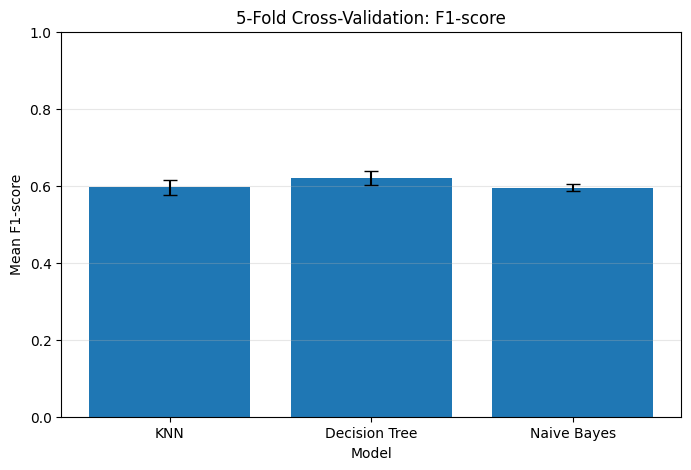

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(
    cv_summary["Model"],
    cv_summary["F1 Mean"],
    yerr=cv_summary["F1 Std"],
    capsize=5
)

plt.title("5-Fold Cross-Validation: F1-score")
plt.xlabel("Model")
plt.ylabel("Mean F1-score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Nhận xét kết quả Cross-validation

| Model | Precision | Recall | F1 | ROC-AUC |
| --- | --- | --- | --- | --- |
| KNN | 0.6126 ± 0.0203 | 0.5819 ± 0.0286 | 0.5965 ± 0.0196 | 0.8291 ± 0.0102 |
| Decision Tree | 0.5162 ± 0.0273 | 0.7759 ± 0.0174 | 0.6194 ± 0.0182 | 0.8151 ± 0.0102 |
| Naive Bayes | 0.4590 ± 0.0064 | 0.8475 ± 0.0208 | 0.5954 ± 0.0080 | 0.8221 ± 0.0126 |

DT có F1 trung bình cao nhất, KNN có Precision và ROC-AUC cao nhất, NB có Recall cao nhất và độ lệch chuẩn F1 nhỏ nhất. Không có mô hình vượt trội ở mọi tiêu chí. CV sau tuning **không phải nested CV**: siêu tham số đã chọn trên cùng training nên các điểm CV/OOF có thể lạc quan. Preprocessing fit riêng trong fold; test không tham gia tuning, CV hoặc chọn threshold.

## 7. OOF probabilities và cost sensitivity trên training set

In [26]:
# OOF probabilities: Pipeline fit training folds; validation chỉ transform.
oof_prob_knn = cross_val_predict(
    best_knn, X_train_raw, y_train_raw,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
oof_prob_dt = cross_val_predict(
    best_dt, X_train_raw, y_train_raw,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
oof_prob_nb = cross_val_predict(
    best_nb, X_train_raw, y_train_raw,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

oof_models = {"KNN": oof_prob_knn, "DT": oof_prob_dt, "NB": oof_prob_nb}
for model_name, probabilities in oof_models.items():
    print(model_name, probabilities.shape, probabilities[:5])

KNN (5634,) [0.57142857 0.42857143 0.04761905 0.0952381  0.57142857]
DT (5634,) [0.42531883 0.85177168 0.03265834 0.03265834 0.65441676]
NB (5634,) [9.99741743e-01 9.98446416e-01 1.30520001e-11 6.34548573e-08
 9.99969340e-01]


In [27]:
best_threshold_knn, threshold_results_knn = (
    find_best_threshold_by_cost(
        y_train_raw,
        oof_prob_knn,
        fn_cost=cost_fn_test,
        fp_cost=cost_fp_test
    )
)

best_threshold_dt, threshold_results_dt = (
    find_best_threshold_by_cost(
        y_train_raw,
        oof_prob_dt,
        fn_cost=cost_fn_test,
        fp_cost=cost_fp_test
    )
)

best_threshold_nb, threshold_results_nb = (
    find_best_threshold_by_cost(
        y_train_raw,
        oof_prob_nb,
        fn_cost=cost_fn_test,
        fp_cost=cost_fp_test
    )
)

In [28]:
locked_thresholds = {
    "KNN": float(best_threshold_knn["Threshold"]),
    "DT": float(best_threshold_dt["Threshold"]),
    "NB": float(best_threshold_nb["Threshold"])
}

print("Locked thresholds:", locked_thresholds)

Locked thresholds: {'KNN': 0.2, 'DT': 0.25000000000000006, 'NB': 0.8900000000000002}


In [29]:
print("===== BEST COST-SENSITIVE THRESHOLDS =====")

print(
    f"KNN: {best_threshold_knn['Threshold']:.2f} "
    f"| Cost: {best_threshold_knn['Cost']:.0f} "
    f"| FP: {best_threshold_knn['FP']:.0f} "
    f"| FN: {best_threshold_knn['FN']:.0f} "
    f"| Recall: {best_threshold_knn['Recall']:.4f} "
    f"| F1: {best_threshold_knn['F1']:.4f}"
)

print(
    f"DT : {best_threshold_dt['Threshold']:.2f} "
    f"| Cost: {best_threshold_dt['Cost']:.0f} "
    f"| FP: {best_threshold_dt['FP']:.0f} "
    f"| FN: {best_threshold_dt['FN']:.0f} "
    f"| Recall: {best_threshold_dt['Recall']:.4f} "
    f"| F1: {best_threshold_dt['F1']:.4f}"
)

print(
    f"NB : {best_threshold_nb['Threshold']:.2f} "
    f"| Cost: {best_threshold_nb['Cost']:.0f} "
    f"| FP: {best_threshold_nb['FP']:.0f} "
    f"| FN: {best_threshold_nb['FN']:.0f} "
    f"| Recall: {best_threshold_nb['Recall']:.4f} "
    f"| F1: {best_threshold_nb['F1']:.4f}"
)

===== BEST COST-SENSITIVE THRESHOLDS =====
KNN: 0.20 | Cost: 2607 | FP: 1652 | FN: 191 | Recall: 0.8722 | F1: 0.5859
DT : 0.25 | Cost: 2615 | FP: 2110 | FN: 101 | Recall: 0.9324 | F1: 0.5577
NB : 0.89 | Cost: 2609 | FP: 1349 | FN: 252 | Recall: 0.8314 | F1: 0.6083


#### Cost-sensitive threshold selection trên OOF training

Ngưỡng được chọn để tối thiểu hóa Cost = 5 × FN + FP, xét các giá trị từ 0.05 đến 0.95 với bước 0.01. Nếu nhiều ngưỡng đồng chi phí, quy tắc tie-break trong code quyết định ngưỡng được lưu.

Ngưỡng được khóa sau khi chọn trên OOF training, test chỉ dùng để đánh giá.

In [30]:
# Sensitivity trên OOF training; giữ lưới coarse hiện có.
all_cost_sensitivity = []
for model_name, probabilities in oof_models.items():
    for scenario_cost_fn in cost_scenarios:
        results = threshold_analysis(
            y_train_raw, probabilities, thresholds=threshold_grid,
            cost_fn=scenario_cost_fn, cost_fp=1
        )
        best_row = results.loc[results["Total Cost"].idxmin()]
        all_cost_sensitivity.append({
            "Model": model_name,
            "FN:FP Cost Ratio": f"{scenario_cost_fn}:1",
            "Best Threshold": best_row["Threshold"],
            "FP": int(best_row["FP"]), "FN": int(best_row["FN"]),
            "Precision": best_row["Precision"], "Recall": best_row["Recall"],
            "F1": best_row["F1"], "Minimum Cost": best_row["Total Cost"]
        })
cost_sensitivity_table = pd.DataFrame(all_cost_sensitivity)
display(cost_sensitivity_table.round(4))

,Model,FN:FP Cost Ratio,Best Threshold,FP,FN,Precision,Recall,F1,Minimum Cost
0,KNN,1:1,0.55,441,724,0.6361,0.5157,0.5696,1165.0
1,KNN,2:1,0.40,827,456,0.5568,0.6950,0.6183,1739.0
2,KNN,5:1,0.20,1652,191,0.4411,0.8722,0.5859,2607.0
3,KNN,10:1,0.10,2218,86,0.3885,0.9425,0.5502,3078.0
4,DT,1:1,0.70,258,940,0.6827,0.3712,0.4809,1198.0
5,DT,2:1,0.50,1094,335,0.5146,0.7759,0.6188,1764.0
6,DT,5:1,0.25,2110,101,0.3978,0.9324,0.5577,2615.0
7,DT,10:1,0.20,2316,80,0.3793,0.9465,0.5415,3116.0
8,NB,1:1,0.90,1345,255,0.4797,0.8294,0.6078,1600.0
9,NB,2:1,0.90,1345,255,0.4797,0.8294,0.6078,1855.0


### Expected Net Benefit — kịch bản nghiệp vụ chính trên OOF training

Giả định: RETENTION_COST = 10, SAVED_CUSTOMER_VALUE = 100,
RETENTION_SUCCESS_RATE = 0.30. Đây là minh họa, không phải giá trị thực từ dataset.

Expected Net Benefit = TP × 100 × 0.30 − (TP + FP) × 10.
nb_*_best, nb_*_results và net_benefit_summary tối ưu riêng trên OOF training.
Không ghi đè locked_thresholds của Cost 5:1; không dùng test để chọn threshold;
minimum cost và maximum net benefit là hai mục tiêu khác nhau.

**Diễn giải chi phí và đơn vị:** Net Benefit = 30 × TP − 10 × (TP + FP) = 20 × TP − 10 × FP. Với P = TP + FN cố định, Net Benefit = 20P − (20FN + 10FP); do đó tối đa hóa Net Benefit tương đương tối thiểu hóa chi phí cơ hội **FN:FP = 2:1**, không phải 5:1. Chi phí 5FN + FP là kịch bản sensitivity riêng, tính bằng đơn vị chi phí tương đối.

10 là chi phí mỗi khách được liên hệ, 100 là giá trị mỗi khách giữ được, cùng một đơn vị tiền giả định và cùng kỳ đánh giá; 30% là xác suất giữ chân thành công giả định đối với khách thực sự churn được nhắm tới. Mô hình giả định chi phí áp dụng cho cả TP/FP, không ghi nhận lợi ích từ FP, chưa xét tác động khác của can thiệp. Dataset không xác minh các giả định này; 100 không phải MonthlyCharges hay CLV đã đo lường. Đây là lợi ích kỳ vọng theo kịch bản so với không can thiệp, không phải lợi nhuận thực nghiệm hoặc decision-curve Net Benefit chuẩn hóa.


In [31]:
nb_knn_best, nb_knn_results = (
    find_best_threshold_by_net_benefit(
        y_train_raw,
        oof_prob_knn,
        retention_cost=RETENTION_COST,
        saved_customer_value=SAVED_CUSTOMER_VALUE,
        retention_success_rate=RETENTION_SUCCESS_RATE
    )
)

nb_dt_best, nb_dt_results = (
    find_best_threshold_by_net_benefit(
        y_train_raw,
        oof_prob_dt,
        retention_cost=RETENTION_COST,
        saved_customer_value=SAVED_CUSTOMER_VALUE,
        retention_success_rate=RETENTION_SUCCESS_RATE
    )
)

nb_nb_best, nb_nb_results = (
    find_best_threshold_by_net_benefit(
        y_train_raw,
        oof_prob_nb,
        retention_cost=RETENTION_COST,
        saved_customer_value=SAVED_CUSTOMER_VALUE,
        retention_success_rate=RETENTION_SUCCESS_RATE
    )
)

In [32]:
net_benefit_summary = pd.DataFrame([
    {
        "Model": "KNN",
        "Threshold": nb_knn_best["Threshold"],
        "TP": nb_knn_best["TP"],
        "FP": nb_knn_best["FP"],
        "FN": nb_knn_best["FN"],
        "Targeted": nb_knn_best["Targeted_Customers"],
        "Expected Saved Value":
            nb_knn_best["Expected_Saved_Value"],
        "Retention Cost":
            nb_knn_best["Retention_Cost"],
        "Expected Net Benefit":
            nb_knn_best["Net_Benefit"]
    },
    {
        "Model": "Decision Tree",
        "Threshold": nb_dt_best["Threshold"],
        "TP": nb_dt_best["TP"],
        "FP": nb_dt_best["FP"],
        "FN": nb_dt_best["FN"],
        "Targeted": nb_dt_best["Targeted_Customers"],
        "Expected Saved Value":
            nb_dt_best["Expected_Saved_Value"],
        "Retention Cost":
            nb_dt_best["Retention_Cost"],
        "Expected Net Benefit":
            nb_dt_best["Net_Benefit"]
    },
    {
        "Model": "Naive Bayes",
        "Threshold": nb_nb_best["Threshold"],
        "TP": nb_nb_best["TP"],
        "FP": nb_nb_best["FP"],
        "FN": nb_nb_best["FN"],
        "Targeted": nb_nb_best["Targeted_Customers"],
        "Expected Saved Value":
            nb_nb_best["Expected_Saved_Value"],
        "Retention Cost":
            nb_nb_best["Retention_Cost"],
        "Expected Net Benefit":
            nb_nb_best["Net_Benefit"]
    }
])

net_benefit_summary

# Khóa riêng chính sách Net Benefit trước khi đọc test predictions.
locked_net_benefit_thresholds = {
    "KNN": float(nb_knn_best["Threshold"]),
    "DT": float(nb_dt_best["Threshold"]),
    "NB": float(nb_nb_best["Threshold"])
}
print("Locked OOF Net Benefit thresholds:", locked_net_benefit_thresholds)
display(net_benefit_summary)


Locked OOF Net Benefit thresholds: {'KNN': 0.39000000000000007, 'DT': 0.4800000000000001, 'NB': 0.9400000000000002}


,Model,Threshold,TP,FP,FN,Targeted,Expected Saved Value,Retention Cost,Expected Net Benefit
0,KNN,0.39,1039.0,827.0,456.0,1866.0,31170.0,18660.0,12510.0
1,Decision Tree,0.48,1160.0,1094.0,335.0,2254.0,34800.0,22540.0,12260.0
2,Naive Bayes,0.94,1229.0,1293.0,266.0,2522.0,36870.0,25220.0,11650.0


### Lưu mô hình và ngưỡng đã khóa

In [33]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
artifacts = {
    "knn.pkl": best_knn, "dt.pkl": best_dt, "nb.pkl": best_nb,
    "locked_thresholds.pkl": locked_thresholds,
    "locked_net_benefit_thresholds.pkl": locked_net_benefit_thresholds,
}
for filename, artifact in artifacts.items():
    joblib.dump(artifact, MODEL_DIR / filename)
    loaded = joblib.load(MODEL_DIR / filename)
    if filename.endswith("thresholds.pkl"):
        assert loaded == artifact
    else:
        np.testing.assert_allclose(loaded.predict_proba(X_train_raw.iloc[:20]),
                                   artifact.predict_proba(X_train_raw.iloc[:20]))
    print("Đã lưu và load kiểm chứng:", MODEL_DIR / filename)

Đã lưu và load kiểm chứng: d:\IT_DOCUMENT\Semester 7 (2026-2027)\DATA MINING\FINAL\Telco-Churn-DM\models\knn.pkl
Đã lưu và load kiểm chứng: d:\IT_DOCUMENT\Semester 7 (2026-2027)\DATA MINING\FINAL\Telco-Churn-DM\models\dt.pkl
Đã lưu và load kiểm chứng: d:\IT_DOCUMENT\Semester 7 (2026-2027)\DATA MINING\FINAL\Telco-Churn-DM\models\nb.pkl
Đã lưu và load kiểm chứng: d:\IT_DOCUMENT\Semester 7 (2026-2027)\DATA MINING\FINAL\Telco-Churn-DM\models\locked_thresholds.pkl
Đã lưu và load kiểm chứng: d:\IT_DOCUMENT\Semester 7 (2026-2027)\DATA MINING\FINAL\Telco-Churn-DM\models\locked_net_benefit_thresholds.pkl


## 8. Test evaluation: baseline, tuned và cost-sensitive

Các tuned Pipelines đã được refit bằng training sau GridSearchCV.
Phần này đánh giá baseline/tuned và cost-sensitive thresholds đã khóa bằng OOF
training. Test không chạy tuning hoặc threshold search.

### 8.1. KNN: baseline và tuned

===== KNN Baseline =====
Accuracy : 0.7551
Precision: 0.5397
Recall   : 0.5267
F1-score : 0.5332
ROC-AUC  : 0.7820

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83      1035
           1       0.54      0.53      0.53       374

    accuracy                           0.76      1409
   macro avg       0.69      0.68      0.68      1409
weighted avg       0.75      0.76      0.75      1409

Confusion Matrix:
[[867 168]
 [177 197]]


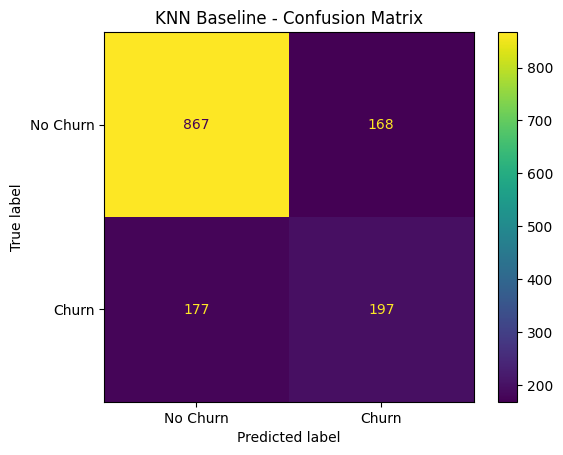

In [34]:
y_predict_knn_baseline = knn_baseline.predict(X_test) # predict 
y_proba_km = knn_baseline.predict_proba(X_test)[:,1]

knn_baseline_result = evaluate_model( # danh gia mo hinh 
  y_test, 
  y_predict_knn_baseline, 
  y_proba_km, 
"KNN Baseline")

- **867 TN: khách hàng thực sự không churn → KNN dự đoán đúng không churn.**
- **168 FP: thực tế không churn → nhưng model báo churn.**
- **177 FN: thực tế churn → model lại bảo không churn.**
- **197 TP: thực tế churn → model phát hiện đúng.**

->  Mô hình cơ sở KNN đạt độ chính xác khoảng 75,5% **Accuracy**. Tuy nhiên, hiệu suất trong việc nhận diện khách hàng rời bỏ dịch vụ còn khá hạn chế, với chỉ số **recall** (độ nhạy) đạt khoảng 52,7%. Mô hình xác định đúng 197 khách hàng rời bỏ nhưng lại bỏ sót 177 trường hợp thực tế. Do đó, cần tiếp tục tinh chỉnh các siêu tham số để cải thiện khả năng phát hiện những khách hàng có nguy cơ rời bỏ dịch vụ.

In [35]:
y_predict_knn_tuned = best_knn.predict(X_test_raw)
y_prob_knn_tuned = best_knn.predict_proba(X_test_raw)[:, 1]

In [36]:
print(best_knn)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                    

===== KNN Tuned =====
Accuracy : 0.7835
Precision: 0.5940
Recall   : 0.5829
F1-score : 0.5884
ROC-AUC  : 0.8239

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.59      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Confusion Matrix:
[[886 149]
 [156 218]]


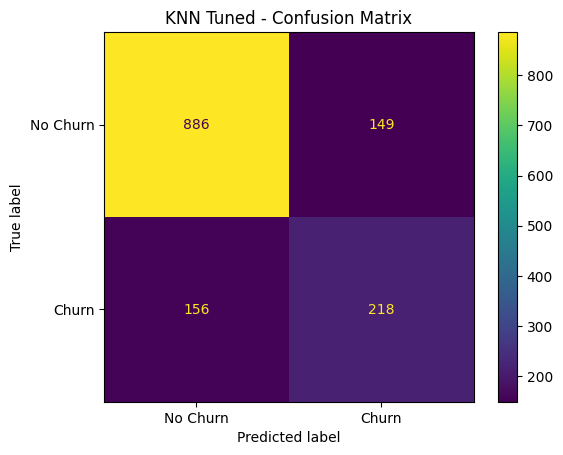

In [37]:
knn_tuned_result = evaluate_model( # danh gia mo hinh 
    y_test,
    y_predict_knn_tuned,
    y_prob_knn_tuned,
    "KNN Tuned"
)

#### Nhận xét KNN sau tuning

KNN chọn k = 21 (Best GridSearchCV F1 = 0.6056). Trên test: Accuracy = 0.7835, Precision = 0.5940, Recall = 0.5829, F1 = 0.5884, ROC-AUC = 0.8239; TN = 886, FP = 149, FN = 156, TP = 218.

Các chỉ số tăng so với baseline, nhưng mô hình vẫn bỏ sót khách hàng churn. Hạ ngưỡng có thể tăng Recall và đồng thời tăng cảnh báo nhầm.

Trong confusion matrix:
- TN: khách hàng No Churn được dự đoán đúng.
- TP: khách hàng Churn được phát hiện đúng.
- FP: khách hàng No Churn bị dự đoán nhầm là Churn, có thể dẫn đến chi phí can thiệp không cần thiết.
- FN: khách hàng Churn bị dự đoán nhầm là No Churn, có thể làm mất cơ hội giữ chân khách hàng.

Trong kịch bản cost-sensitive Cost = 5 × FN + FP, FN được gán chi phí giả định cao gấp năm lần FP. Đây là lựa chọn mô hình hóa để minh họa, không phải tỷ lệ chi phí đã được xác nhận từ doanh nghiệp.

In [38]:
knn_metrics_comparison = compare_model_metrics(
    knn_baseline_result,
    knn_tuned_result
)

print("\nKNN Metrics Comparison:")
print(knn_metrics_comparison)

knn_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_knn_baseline,
    y_predict_knn_tuned
)

print("\nKNN Confusion Matrix Comparison:")
print(knn_confusion_comparison)


KNN Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7551  0.7835       0.0284
Precision    0.5397  0.5940       0.0543
Recall       0.5267  0.5829       0.0561
F1-score     0.5332  0.5884       0.0552
ROC-AUC      0.7820  0.8239       0.0419

KNN Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       867    886      19
FP       168    149     -19
FN       177    156     -21
TP       197    218      21


#### Kết luận so sánh KNN

Sau tuning, Accuracy tăng 0.7551 → 0.7835; Precision 0.5397 → 0.5940; Recall 0.5267 → 0.5829; F1 0.5332 → 0.5884; ROC-AUC 0.7820 → 0.8239. TP tăng từ 197 lên 218, FN giảm từ 177 xuống 156.

Siêu tham số được chọn trên training; cải thiện trên lần chia test này không đảm bảo lặp lại trên dữ liệu mới.

### 8.2. Decision Tree: baseline và tuned

===== Decision Tree Baseline =====
Accuracy : 0.7211
Precision: 0.4753
Recall   : 0.4893
F1-score : 0.4822
ROC-AUC  : 0.6468

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1035
           1       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409

Confusion Matrix:
[[833 202]
 [191 183]]


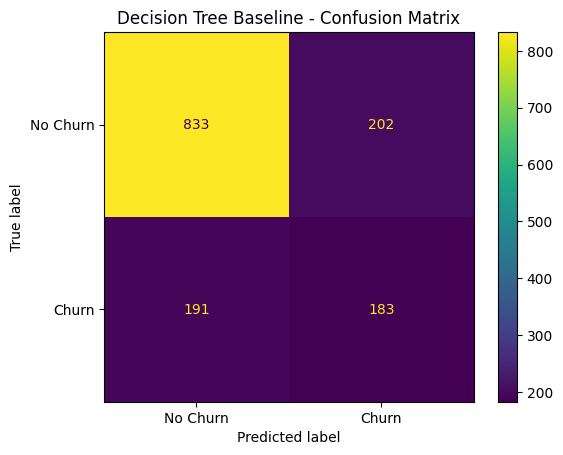

In [39]:
y_predict_dt_baseline = dt_baseline.predict(X_test)
y_prob_dt_baseline =  dt_baseline.predict_proba(X_test)[:,1]

dt_baseline_result = evaluate_model(
  y_test,
  y_predict_dt_baseline,
  y_prob_dt_baseline,
  "Decision Tree Baseline"
)

#### Nhận xét
Decision Tree Baseline đạt:

- **Accuracy = 72.11%**
- **Precision = 47.53%**
- **Recall = 48.93%**
- **F1-score = 48.22%**
- **ROC-AUC = 64.68%**

Confusion Matrix cho thấy mô hình phát hiện đúng **183** khách hàng Churn,
nhưng đồng thời bỏ sót **191** trường hợp Churn (False Negative).

Kết quả baseline cho thấy khả năng nhận diện lớp Churn còn hạn chế.
Đặc biệt, Decision Tree với cấu hình mặc định có thể tạo cây quá phức tạp
do không giới hạn max_depth, làm tăng nguy cơ overfitting.

Kết quả này là cơ sở để so sánh với cây đã được kiểm soát độ phức tạp
bằng hyperparameter tuning ở mục 5.2.



In [40]:
y_predict_dt_tuned = best_dt.predict(X_test_raw)
y_prob_dt_tuned = best_dt.predict_proba(X_test_raw)[:, 1]

===== Decision Tree Tuned =====
Accuracy : 0.7459
Precision: 0.5140
Recall   : 0.7834
F1-score : 0.6208
ROC-AUC  : 0.8144

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.75      0.76      1409

Confusion Matrix:
[[758 277]
 [ 81 293]]


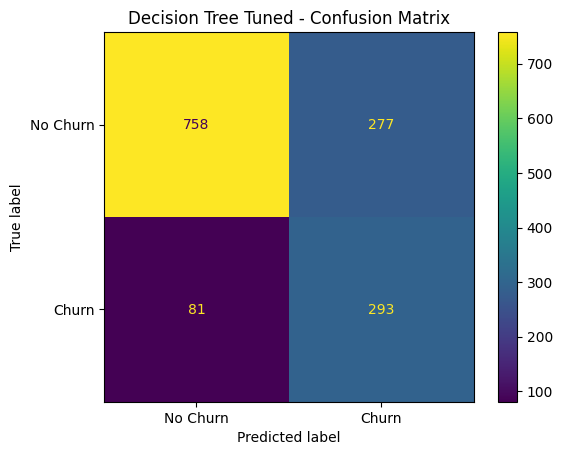

In [41]:
dt_tuned_result = evaluate_model(
  y_test,
  y_predict_dt_tuned,
  y_prob_dt_tuned,
  "Decision Tree Tuned"
)

In [42]:
dt_metrics_comparison = compare_model_metrics(
    dt_baseline_result,
    dt_tuned_result
)

print("\nDecision Tree Metrics Comparison:")
print(dt_metrics_comparison)

dt_confusion_comparison = compare_confusion_matrix(
    y_test, 
    y_predict_dt_baseline,
    y_predict_dt_tuned
)

print("\nDecision Tree Confusion Matrix Comparison:")
print(dt_confusion_comparison)


Decision Tree Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7211  0.7459       0.0248
Precision    0.4753  0.5140       0.0387
Recall       0.4893  0.7834       0.2941
F1-score     0.4822  0.6208       0.1385
ROC-AUC      0.6468  0.8144       0.1676

Decision Tree Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       833    758     -75
FP       202    277      75
FN       191     81    -110
TP       183    293     110


### 8.3. Naive Bayes: baseline và tuned

===== Naive Bayes Baseline =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8093

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


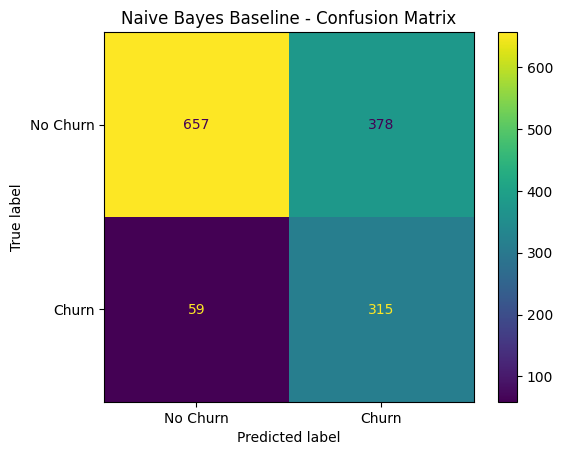

In [43]:
y_predict_nb_baseline = nb_baseline.predict(X_test)
y_prob_nb_baseline = nb_baseline.predict_proba(X_test)[:,1]

nb_baseline_result = evaluate_model(
    y_test,
    y_predict_nb_baseline,
    y_prob_nb_baseline,
    "Naive Bayes Baseline"
)

#### Nhận xét kết quả Baseline

GaussianNB baseline đạt Accuracy = 68.99%, F1 = 59.04% và ROC-AUC = 80.93%. Recall cao (84.22%): phát hiện 315/374 khách hàng churn, bỏ sót 59. Tuy nhiên, Precision chỉ 45.45% và có 378 False Positive.

Mô hình ưu tiên phát hiện churn nhưng tạo nhiều cảnh báo nhầm.

In [44]:
y_predict_nb_tuned = best_nb.predict(X_test_raw)
y_prob_nb_tuned = best_nb.predict_proba(X_test_raw)[:, 1]

===== Naive Bayes Tuned =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8094

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


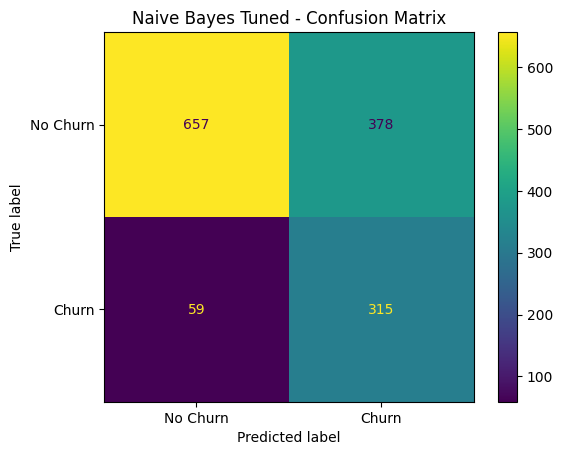

In [45]:
nb_tuned_result = evaluate_model(
    y_test, 
    y_predict_nb_tuned,
    y_prob_nb_tuned,
    "Naive Bayes Tuned"
)

#### Nhận xét sau Hyperparameter Tuning

GaussianNB chọn var_smoothing = 0.001 (Best CV F1 = 0.5956). Tuning không đổi nhãn dự đoán trên test: TN = 657, FP = 378, FN = 59, TP = 315; ROC-AUC tăng rất nhỏ từ 0.809341 lên 0.809414. Không có cải thiện đáng kể ở các chỉ số còn lại.

In [46]:
nb_metrics_comparison = compare_model_metrics(
    nb_baseline_result,
    nb_tuned_result
)

print("\nNaive Bayes Metrics Comparison:")
print(nb_metrics_comparison)

nb_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_nb_baseline,
    y_predict_nb_tuned
)

print("\nNaive Bayes Confusion Matrix Comparison:")
print(nb_confusion_comparison)


Naive Bayes Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.6899  0.6899       0.0000
Precision    0.4545  0.4545       0.0000
Recall       0.8422  0.8422       0.0000
F1-score     0.5904  0.5904       0.0000
ROC-AUC      0.8093  0.8094       0.0001

Naive Bayes Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       657    657       0
FP       378    378       0
FN        59     59       0
TP       315    315       0


### 8.4. So sánh ba tuned models

In [47]:
final_model_comparison = pd.DataFrame([
    knn_tuned_result,
    dt_tuned_result,
    nb_tuned_result
])

final_model_comparison = final_model_comparison[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ]
]

final_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,KNN Tuned,0.7835,0.5940,0.5829,0.5884,0.8239
1,Decision Tree Tuned,0.7459,0.5140,0.7834,0.6208,0.8144
2,Naive Bayes Tuned,0.6899,0.4545,0.8422,0.5904,0.8094


#### So sánh kết quả test và CV

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
| --- | --- | --- | --- | --- | --- |
| KNN Tuned | 0.7835 | 0.5940 | 0.5829 | 0.5884 | 0.8239 |
| Decision Tree Tuned | 0.7459 | 0.5140 | 0.7834 | 0.6208 | 0.8144 |
| Naive Bayes Tuned | 0.6899 | 0.4545 | 0.8422 | 0.5904 | 0.8094 |

KNN có Accuracy/Precision/ROC-AUC test cao nhất, DT có F1 cao nhất, NB có Recall cao nhất. Thứ tự F1 nhất quán với CV; riêng ROC-AUC, NB cao hơn DT trên CV nhưng thấp hơn DT trên test. Chênh lệch F1 hoặc AUC không được kiểm định trực tiếp bởi McNemar. Test dùng báo cáo cuối cùng, không dùng để điều chỉnh cấu hình.

In [48]:
# Tái sử dụng probabilities đã tính; không predict_proba lần thứ hai.
test_probabilities = {
    "KNN": y_prob_knn_tuned, "DT": y_prob_dt_tuned, "NB": y_prob_nb_tuned
}
test_predictions = {
    "KNN": y_predict_knn_tuned, "DT": y_predict_dt_tuned, "NB": y_predict_nb_tuned
}
error_rows = []
for model_name, predictions in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    error_rows.append({"Model": model_name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
error_comparison = pd.DataFrame(error_rows)
display(error_comparison)

,Model,TN,FP,FN,TP
0,KNN,886,149,156,218
1,DT,758,277,81,293
2,NB,657,378,59,315


### McNemar: so sánh dự đoán ghép cặp

Kiểm định exact trên cùng test set, sử dụng nhãn từ `predict` của tuned models. H0: hai mô hình có cùng xác suất dự đoán đúng. p > 0.05: chưa đủ bằng chứng bác bỏ H0, không chứng minh tương đương. p ≤ 0.05: có bằng chứng khác biệt. McNemar không kiểm định trực tiếp F1 hoặc ROC-AUC. Ba p-value được báo cáo chưa hiệu chỉnh đa kiểm định, đây là giới hạn khi diễn giải đồng thời cả ba cặp.

In [49]:
from itertools import combinations
from statsmodels.stats.contingency_tables import mcnemar

mcnemar_rows = []
truth = np.asarray(y_test).ravel()
for name_a, name_b in combinations(test_predictions, 2):
    correct_a = np.asarray(test_predictions[name_a]) == truth
    correct_b = np.asarray(test_predictions[name_b]) == truth
    assert correct_a.shape == correct_b.shape == truth.shape
    table = np.array([[np.sum(correct_a & correct_b), np.sum(correct_a & ~correct_b)],
                      [np.sum(~correct_a & correct_b), np.sum(~correct_a & ~correct_b)]])
    # Exact conditional binomial test is valid for all discordant sample sizes.
    result = mcnemar(table, exact=True)
    mcnemar_rows.append({"Model A": name_a, "Model B": name_b,
        "Disagreement A correct / B wrong": int(table[0, 1]),
        "Disagreement A wrong / B correct": int(table[1, 0]),
        "p-value": float(result.pvalue),
        "Kết luận (alpha=0.05)": "Có bằng chứng khác biệt" if result.pvalue <= .05 else "Chưa đủ bằng chứng bác bỏ H0"})
mcnemar_results = pd.DataFrame(mcnemar_rows)
display(mcnemar_results)


,Model A,Model B,Disagreement A correct / B wrong,Disagreement A wrong / B correct,p-value,Kết luận (alpha=0.05)
0,KNN,DT,153,100,1.038789e-03,Có bằng chứng khác biệt
1,KNN,NB,230,98,2.242359e-13,Có bằng chứng khác biệt
2,DT,NB,162,83,5.029248e-07,Có bằng chứng khác biệt


#### Nhận xét Error Analysis

- KNN: TN 886, FP 149, FN 156, TP 218.
- DT: TN 758, FP 277, FN 81, TP 293.
- NB: TN 657, FP 378, FN 59, TP 315.

DT phát hiện nhiều churn hơn KNN nhưng tạo nhiều FP hơn. NB bỏ sót ít nhất, đồng thời cảnh báo sai nhiều nhất. KNN có ít FP nhất. Lựa chọn phụ thuộc tổn thất của từng loại lỗi và năng lực can thiệp.

### 8.5. Đánh giá threshold đã khóa

In [50]:
threshold_test_rows = []
for model_name, probabilities in test_probabilities.items():
    auc = roc_auc_score(y_test, probabilities)
    for setting, threshold in [
        ("Default", 0.50), ("Cost-sensitive", locked_thresholds[model_name])
    ]:
        threshold_test_rows.append({
            "Model": model_name, "Setting": setting,
            **metrics_at_threshold(
                y_test, probabilities, threshold, cost_fn_test, cost_fp_test
            ),
            "ROC-AUC": auc
        })
default_vs_cost = pd.DataFrame(threshold_test_rows)
display(default_vs_cost.round(4))

# Đánh giá một lần các chính sách đã khóa; không tìm ngưỡng trên test.
net_benefit_test_rows = []
for model_name, probabilities in test_probabilities.items():
    metrics = metrics_at_threshold(
        y_test, probabilities, locked_net_benefit_thresholds[model_name],
        cost_fn=2, cost_fp=1
    )
    primary_cost = metrics.pop("Total Cost")
    net_benefit = (
        SAVED_CUSTOMER_VALUE * RETENTION_SUCCESS_RATE * metrics["TP"]
        - RETENTION_COST * (metrics["TP"] + metrics["FP"])
    )
    assert np.isclose(net_benefit, 20 * np.sum(np.asarray(y_test) == 1) - 10 * primary_cost)
    net_benefit_test_rows.append({
        "Model": model_name, **metrics,
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Net Benefit (money units)": net_benefit,
        "Cost 2FN+FP (relative units)": primary_cost,
        "Opportunity Cost 20FN+10FP (money units)": 10 * primary_cost,
        "Sensitivity Cost 5FN+FP (relative units)": 5 * metrics["FN"] + metrics["FP"]
    })
locked_net_benefit_test = pd.DataFrame(net_benefit_test_rows)
display(locked_net_benefit_test.round(4))


,Model,Setting,Threshold,TN,FP,FN,TP,Precision,Recall,F1,Total Cost,ROC-AUC
0,KNN,Default,0.50,886,149,156,218,0.5940,0.5829,0.5884,929,0.8239
1,KNN,Cost-sensitive,0.20,615,420,41,333,0.4422,0.8904,0.5909,625,0.8239
2,DT,Default,0.50,758,277,81,293,0.5140,0.7834,0.6208,682,0.8144
3,DT,Cost-sensitive,0.25,537,498,26,348,0.4113,0.9305,0.5705,628,0.8144
4,NB,Default,0.50,657,378,59,315,0.4545,0.8422,0.5904,673,0.8094
5,NB,Cost-sensitive,0.89,695,340,68,306,0.4737,0.8182,0.6000,680,0.8094


,Model,Threshold,TN,FP,FN,TP,Precision,Recall,F1,ROC-AUC,Net Benefit (money units),Cost 2FN+FP (relative units),Opportunity Cost 20FN+10FP (money units),Sensitivity Cost 5FN+FP (relative units)
0,KNN,0.39,813,222,115,259,0.5385,0.6925,0.6058,0.8239,2960.0,452,4520,797
1,DT,0.48,758,277,81,293,0.5140,0.7834,0.6208,0.8144,3090.0,439,4390,682
2,NB,0.94,703,332,77,297,0.4722,0.7941,0.5922,0.8094,2620.0,486,4860,717


Threshold mặc định là 0.50. Cost-sensitive prediction dùng probability >=
locked_thresholds[model_name]. Cost 5:1 được tính từ confusion matrix: 5 * FN + FP.

#### Cost-sensitive Threshold Analysis
Ngưỡng OOF tối thiểu hóa Cost = 5 × FN + FP:
- KNN: threshold 0.20, OOF cost 2607.
- Decision Tree: threshold 0.25, OOF cost 2615.
- GaussianNB: threshold 0.89, OOF cost 2609.
Chi phí OOF gần nhau, chi phí test lần lượt là 625, 628 và 680. Trên test, Recall tăng với KNN (0.5829 → 0.8904) và Decision Tree (0.7834 → 0.9305), nhưng số FP tăng, GaussianNB có cost 673 → 680.

Theo giả định Net Benefit (chi phí 10, giá trị 100, thành công 0.30), ngưỡng OOF tối ưu là KNN 0.39, Decision Tree 0.48, GaussianNB 0.94; benefit lần lượt là 12510, 12260, 11650. Đây là mục tiêu khác với cost 5:1 và không ghi đè ngưỡng đã khóa cho mục tiêu kia.

Lựa chọn chính: Decision Tree theo tiêu chí F1 đã xác định trước. Các chi phí và Net Benefit chỉ mang tính minh họa; không chọn lại ngưỡng trên test.

## 9. Error analysis

#### Error Analysis

- FP: khách hàng không churn nhưng bị cảnh báo churn, có thể làm tăng chi phí tiếp cận.
- FN: khách hàng churn nhưng mô hình dự đoán không churn, có thể bỏ lỡ cơ hội giữ chân.
Khi đọc tỷ lệ lỗi theo nhóm, cần xem cả số lượng mẫu và mẫu số. Kết quả mô tả lỗi dự đoán, không chứng minh quan hệ nhân quả.

In [51]:
error_analysis = X_test_raw.reset_index(drop=True).copy()
error_analysis["Actual_Churn"] = np.asarray(y_test).ravel()
for model_name, predictions in test_predictions.items():
    error_analysis[f"{model_name}_Prediction"] = predictions
    error_analysis[f"{model_name}_Result"] = [
        classify_prediction(actual, predicted)
        for actual, predicted in zip(error_analysis["Actual_Churn"], predictions)
    ]
display(error_analysis.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,KNN_Prediction,KNN_Result,DT_Prediction,DT_Result,NB_Prediction,NB_Result
0,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Credit card (automatic),114.05,8468.20,0,0,TN,0,TN,0,TN
1,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Credit card (automatic),100.15,908.55,0,1,FP,1,FP,1,FP
2,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),78.35,3211.20,0,0,TN,0,TN,0,TN
3,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Electronic check,78.20,1468.75,0,0,TN,1,FP,1,FP
4,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),82.65,5919.35,0,0,TN,0,TN,0,TN


In [52]:
numeric_error_profiles = {}
for model_name in test_predictions:
    profile = (
        error_analysis.groupby(f"{model_name}_Result")[numeric_features]
        .mean().round(2)
    )
    numeric_error_profiles[model_name] = profile
    print(f"\n===== {model_name} =====")
    print(profile.loc[["FP", "FN"]])

for model_name in test_predictions:
    print(f"\n===== {model_name} =====")
    for feature in categorical_features:
        print(f"\n{feature}")
        print(categorical_error_profile(
            error_analysis, feature, f"{model_name}_Result",
            groups=["FP", "FN"], decimals=1
        ))


===== KNN =====
            tenure  MonthlyCharges  TotalCharges
KNN_Result                                      
FP           17.10           80.67       1497.44
FN           24.55           64.11       2071.62

===== DT =====
           tenure  MonthlyCharges  TotalCharges
DT_Result                                      
FP          19.70           72.16       1759.01
FN          33.83           67.80       2739.98

===== NB =====
           tenure  MonthlyCharges  TotalCharges
NB_Result                                      
FP          23.88           72.81       1880.13
FN          30.36           60.34       2670.53

===== KNN =====

Contract
Contract    Month-to-month  One year  Two year
KNN_Result                                    
FN                    72.4      21.8       5.8
FP                    96.6       2.7       0.7

InternetService
InternetService   DSL  Fiber optic    No
KNN_Result                              
FN               44.9         39.1  16.0
FP              

In [53]:
segment_results = []

for model in ["KNN", "DT", "NB"]:

    for feature in categorical_features:

        result = segment_error_rate(
            error_analysis,
            model,
            feature
        )

        result.insert(0, "Feature", feature)
        result.insert(0, "Model", model)

        # Đổi tên category thành một cột chung
        result = result.rename(
            columns={feature: "Category"}
        )

        segment_results.append(result)

business_error_summary = pd.concat(
    segment_results,
    ignore_index=True
)

display(business_error_summary.round(4))
# Bảng Contract lấy từ cùng nguồn, không tính lại segment_error_rate.
for model_name in test_predictions:
    print(f"\n===== {model_name} - Contract =====")
    display(business_error_summary.loc[
        (business_error_summary["Model"] == model_name)
        & (business_error_summary["Feature"] == "Contract")
    ].round(4))

# Mẫu số là khách thực sự churn trong hợp đồng dài hạn, tại predict mặc định.
dt_long_contracts = business_error_summary.loc[
    (business_error_summary["Model"] == "DT")
    & (business_error_summary["Feature"] == "Contract")
    & business_error_summary["Category"].isin(["One year", "Two year"])
]
long_contract_churn = int(dt_long_contracts["Actual Churn"].sum())
long_contract_fn = int(dt_long_contracts["FN"].sum())
print(f"DT long-contract FN / actual churn: {long_contract_fn}/{long_contract_churn}")


,Model,Feature,Category,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,KNN,Contract,Two year,327,1,0.0031,9,9,1.0000
1,KNN,Contract,Month-to-month,444,144,0.3243,329,113,0.3435
2,KNN,Contract,One year,264,4,0.0152,36,34,0.9444
3,KNN,InternetService,Fiber optic,361,127,0.3518,252,61,0.2421
4,KNN,InternetService,DSL,387,22,0.0568,97,70,0.7216
5,KNN,InternetService,No,287,0,0.0000,25,25,1.0000
6,KNN,PaymentMethod,Credit card (automatic),258,16,0.0620,51,28,0.5490
7,KNN,PaymentMethod,Electronic check,268,93,0.3470,206,52,0.2524
8,KNN,PaymentMethod,Bank transfer (automatic),243,17,0.0700,57,37,0.6491
9,KNN,PaymentMethod,Mailed check,266,23,0.0865,60,39,0.6500



===== KNN - Contract =====


,Model,Feature,Category,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,KNN,Contract,Two year,327,1,0.0031,9,9,1.0000
1,KNN,Contract,Month-to-month,444,144,0.3243,329,113,0.3435
2,KNN,Contract,One year,264,4,0.0152,36,34,0.9444



===== DT - Contract =====


,Model,Feature,Category,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
16,DT,Contract,Two year,327,0,0.0000,9,9,1.0000
17,DT,Contract,Month-to-month,444,277,0.6239,329,36,0.1094
18,DT,Contract,One year,264,0,0.0000,36,36,1.0000



===== NB - Contract =====


,Model,Feature,Category,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
32,NB,Contract,Two year,327,0,0.0000,9,9,1.0000
33,NB,Contract,Month-to-month,444,344,0.7748,329,24,0.0729
34,NB,Contract,One year,264,34,0.1288,36,26,0.7222


DT long-contract FN / actual churn: 45/45


#### Phân tích lỗi theo phân khúc

Các bảng Contract, InternetService, PaymentMethod, TechSupport và OnlineSecurity dùng chung test_predictions. Khi so sánh FP/FN giữa nhóm, cần xem cả số mẫu và tỷ lệ, kết quả chỉ mô tả lỗi trên test.

### Phân tích sâu Decision Tree: FN–TP và FP–TN

In [54]:
# Giữ quy tắc >= 0.5 của phân tích DT gốc, kể cả trường hợp xác suất đúng 0.5.
y_pred_dt_default = (test_probabilities["DT"] >= 0.5).astype(int)
error_df = error_analysis[list(X_test_raw.columns) + ["Actual_Churn"]].copy()
error_df["Predicted_Churn"] = y_pred_dt_default
error_df["Churn_Probability"] = test_probabilities["DT"]
error_df["Error_Type"] = [
    classify_prediction(actual, predicted)
    for actual, predicted in zip(error_df["Actual_Churn"], y_pred_dt_default)
]
display(error_df["Error_Type"].value_counts())
print("False Negatives :", (error_df["Error_Type"] == "FN").sum())
print("False Positives :", (error_df["Error_Type"] == "FP").sum())

# Chỉ dùng chung thống kê khi predictions thực sự giống nhau.
if np.array_equal(y_pred_dt_default, test_predictions["DT"]):
    error_numeric_summary = numeric_error_profiles["DT"].copy()
    error_numeric_summary.index.name = "Error_Type"
else:
    error_numeric_summary = (
        error_df.groupby("Error_Type")[numeric_features].mean().round(2)
    )
display(error_numeric_summary)

Error_Type
TN    758
TP    293
FP    277
FN     81
Name: count, dtype: int64

False Negatives : 81
False Positives : 277


,tenure,MonthlyCharges,TotalCharges
Error_Type,,,
FN,33.83,67.80,2739.98
FP,19.70,72.16,1759.01
TN,44.00,56.86,2758.05
TP,11.66,74.14,1030.48


In [55]:
contract_error_profile = categorical_error_profile(
    error_df,
    "Contract"
)

display(contract_error_profile)

internet_error_profile = categorical_error_profile(
    error_df,
    "InternetService"
)

display(internet_error_profile)

Contract,Month-to-month,One year,Two year
Error_Type,,,
FN,44.44,44.44,11.11
FP,100.00,0.00,0.00
TN,22.03,34.83,43.14
TP,100.00,0.00,0.00


InternetService,DSL,Fiber optic,No
Error_Type,,,
FN,51.85,37.04,11.11
FP,14.08,71.84,14.08
TN,45.91,21.37,32.72
TP,18.77,75.77,5.46


#### Phân tích đặc điểm dự đoán sai của DT

FN có tenure trung bình **33.83 tháng**, cao hơn TP **11.66 tháng**; MonthlyCharges tương ứng **67.80** và **74.14**. Mô hình bỏ sót một số khách hàng churn có thời gian gắn bó dài hơn, trong khi phát hiện tốt hơn các khách mới.

FP có tenure **19.70 tháng**, thấp hơn TN **44.00 tháng**; MonthlyCharges **72.16** so với **56.86**. Nhóm không churn nhưng mới tham gia và trả phí cao có thể bị cảnh báo nhầm nhiều hơn. Đây là profile mô tả, cần đối chiếu bảng Contract/InternetService và số mẫu trước quyết định nghiệp vụ.

Với ngưỡng DT 0.25 khóa từ OOF, FN test giảm 81 → 26 nhưng FP tăng 277 → 498; cost 5:1 giảm 682 → 628. Giả định này không xác lập một ngưỡng tối ưu tuyệt đối cho doanh nghiệp.

**Giới hạn phân khúc hợp đồng:** đã xác nhận DT bỏ sót **45/45** khách churn hợp đồng dài hạn (One year: 36/36; Two year: 9/9), trong tổng FN = 81 tại ngưỡng mặc định. Đây là điểm mù của chính sách mặc định, dù F1 tổng thể tốt nhất. Cây phụ thuộc mạnh vào Contract (đối chiếu impurity importance ở mục 10); phân khúc dài hạn có thể nhận điểm thấp và bị bỏ qua trong danh sách retention. Đây là mô tả trên mẫu test, không chứng minh hợp đồng gây churn hay chứng minh lỗi xảy ra với mọi khách dài hạn. Cần cơ chế rà soát nghiệp vụ cho nhóm này; không sửa mô hình hoặc ngưỡng dựa trên nhãn test hiện tại.


## 10. Feature importance và driver insights

Decision Tree Tuned được dùng để phân tích feature importance vì có thể diễn giải qua các luật chia của cây. Importance phản ánh mức sử dụng đặc trưng trong mô hình, không cho biết chiều liên hệ hay quan hệ nhân quả với churn.

In [56]:
feature_importance_df = pd.DataFrame({
    "Feature": best_dt.named_steps["preprocessor"].get_feature_names_out(),
    "Importance": best_dt.named_steps["clf"].feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance_df.head(10)

,Feature,Importance
0,cat__Contract_Month-to-month,0.699123
1,cat__InternetService_Fiber optic,0.124091
2,num__tenure,0.103713
3,num__MonthlyCharges,0.042224
4,cat__Contract_Two year,0.016236
5,cat__OnlineSecurity_No,0.014614
6,num__SeniorCitizen,0.000000
7,cat__StreamingMovies_No,0.000000
8,cat__TechSupport_No internet service,0.000000
9,cat__TechSupport_Yes,0.000000


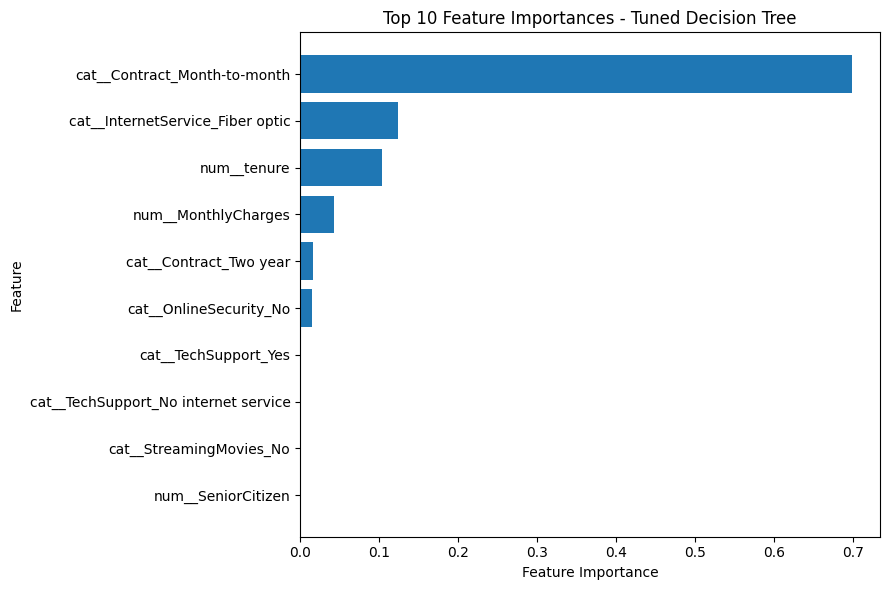

In [57]:
top_10_features = (
    feature_importance_df
    .head(10)
    .sort_values("Importance")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_10_features["Feature"],
    top_10_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Tuned Decision Tree")

plt.tight_layout()
plt.show()

#### Top Churn Drivers and Direction of Association

Feature importance không cho biết đặc trưng liên hệ với churn theo chiều tăng hay giảm. Vì vậy, notebook đối chiếu importance với tỷ lệ churn theo nhóm. Đây là thống kê mô tả, có thể chịu ảnh hưởng của các biến khác và cách lấy mẫu.

In [58]:
# df_raw["Churn"] đã được mã hóa 0/1 tại mục dữ liệu; không map lại Yes/No.
driver_df = df_raw.copy()
driver_df["Churn_binary"] = driver_df["Churn"]
assert driver_df["Churn_binary"].notna().all()
assert set(driver_df["Churn_binary"].unique()) == {0, 1}

In [59]:
contract_churn = churn_rate_by_group(driver_df, "Contract", sort_by_rate=True)
internet_churn = churn_rate_by_group(driver_df, "InternetService", sort_by_rate=True)
driver_df["Tenure_Group"] = pd.cut(
    driver_df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)
tenure_churn = churn_rate_by_group(driver_df, "Tenure_Group", observed=True)
driver_df["MonthlyCharges_Group"] = pd.qcut(
    driver_df["MonthlyCharges"], q=4,
    labels=["Q1 - Lowest", "Q2", "Q3", "Q4 - Highest"]
)
monthly_churn = churn_rate_by_group(driver_df, "MonthlyCharges_Group", observed=True)
for driver_table in [contract_churn, internet_churn, tenure_churn, monthly_churn]:
    display(driver_table.round(2))

,Churn_Rate,Customers
Contract,,
Month-to-month,42.71,3875
One year,11.27,1473
Two year,2.83,1695


,Churn_Rate,Customers
InternetService,,
Fiber optic,41.89,3096
DSL,18.96,2421
No,7.40,1526


,Churn_Rate,Customers
Tenure_Group,,
0-12 months,47.44,2186
13-24 months,28.71,1024
25-48 months,20.39,1594
49-72 months,9.51,2239


,Churn_Rate,Customers
MonthlyCharges_Group,,
Q1 - Lowest,11.24,1762
Q2,24.58,1766
Q3,37.51,1757
Q4 - Highest,32.88,1758


| Driver                        | DT Importance hiện tại | Quan sát từ dữ liệu                                              |
| ----------------------------- | ------------: | ---------------------------------------------------------------- |
| Contract – Month-to-month | 0.6991 | Month-to-month churn **42.71%**, One year 11.27%, Two year 2.83% |
| InternetService – Fiber optic | 0.1241 | Fiber optic **41.89%**, DSL 18.96%, No Internet 7.40% |
| tenure | 0.1037 | 0–12 tháng **47.44%** → 49–72 tháng chỉ **9.51%** |
| MonthlyCharges | 0.0422 | Q1 11.24%, Q2 24.58%, **Q3 37.51%**, Q4 32.88% |

#### Driver-based Insights & Business Interpretation

Importance tính lại: Contract_Month-to-month 0.6991, InternetService_Fiber optic 0.1241, tenure 0.1037, MonthlyCharges 0.0422. Đây là mức giảm impurity, không cho biết chiều tác động hoặc quan hệ nhân quả. Các tỷ lệ churn dưới đây đã được kiểm tra lại từ dữ liệu gốc.

**1. Contract type**

Contract_Month-to-month là đặc trưng hợp đồng được đối chiếu trong phân tích này. Khách hàng sử dụng hợp đồng Month-to-month có churn rate 42.71%,
cao hơn đáng kể so với One year (11.27%) và Two year (2.83%).

Kết quả cho thấy nhóm khách hàng sử dụng hợp đồng ngắn hạn là một phân khúc
có rủi ro churn đáng chú ý. Trong thực tế, doanh nghiệp có thể cân nhắc các chương
trình khuyến khích khách hàng phù hợp chuyển sang hợp đồng dài hạn, chẳng hạn
ưu đãi gia hạn hoặc loyalty benefits.

**2. Customer tenure**

tenure được đối chiếu với churn rate theo thời gian gắn bó. Churn rate giảm rõ
rệt khi thời gian gắn bó tăng: khách hàng trong 0–12 tháng có churn rate 47.44%,
trong khi nhóm 49–72 tháng chỉ còn 9.51%.

Điều này cho thấy khách hàng mới là nhóm cần được chú ý trong chiến lược retention.
Doanh nghiệp có thể ưu tiên onboarding, hỗ trợ và các hoạt động chăm sóc trong
những tháng đầu của vòng đời khách hàng.

**3. Internet service**

InternetService_Fiber optic được đối chiếu với churn rate theo loại dịch vụ.
Nhóm sử dụng Fiber optic có churn rate 41.89%, so với 18.96% ở DSL và
7.40% ở nhóm không sử dụng Internet Service.

Kết quả xác định khách hàng Fiber optic là một phân khúc có churn rate quan sát
được tương đối cao. Tuy nhiên, phân tích hiện tại chưa xác định nguyên nhân của
sự khác biệt này. Doanh nghiệp có thể xem đây là nhóm cần điều tra thêm về
chất lượng dịch vụ, giá, hỗ trợ kỹ thuật hoặc các yếu tố liên quan trước khi đưa
ra chính sách cụ thể.

**4. Monthly charges**

MonthlyCharges được đối chiếu với churn rate theo mức phí. Churn rate tăng từ 11.24% ở quartile
thấp nhất lên 24.58% ở Q2 và đạt 37.51% ở Q3, nhưng giảm nhẹ xuống 32.88%
ở quartile cao nhất.

Do đó, dữ liệu không hỗ trợ kết luận đơn giản rằng MonthlyCharges càng cao thì
churn càng tăng. Thay vào đó, mức phí hàng tháng có mối liên hệ phi tuyến với
churn và có thể tương tác với các yếu tố khác như loại hợp đồng hoặc loại dịch vụ.

**Business interpretation**

Mức độ DT balanced sử dụng các đặc trưng cần đọc từ bảng importance hiện tại. Kết hợp với churn
rate quan sát được, kết quả gợi ý rằng nhóm khách hàng hợp đồng Month-to-month,
khách hàng mới và khách hàng Fiber optic là những phân khúc đáng được doanh
nghiệp theo dõi trong chiến lược retention.

Các kết quả trên phản ánh association trong dataset và hành vi của mô hình,
không chứng minh rằng các đặc trưng này trực tiếp gây ra churn.

## 11. Risk × Value segmentation

Phần này kết hợp điểm rủi ro churn với MonthlyCharges làm proxy cho giá trị khách hàng, nhằm minh họa cách phân nhóm ưu tiên chăm sóc.

Phân tích kết hợp hai chiều:

- Risk: điểm rủi ro dự đoán từ Decision Tree, dùng làm điểm ưu tiên giữ chân khách hàng.
- Value: MonthlyCharges của khách hàng.

`predict_proba()` trả về xác suất ước lượng, nhưng các giá trị này chưa được hiệu chỉnh (calibration). Trong mục này, giá trị đầu ra predict_proba chưa hiệu chỉnh được sử dụng để xếp hạng tương đối và ưu tiên nghiệp vụ, không phải ước lượng chính xác xác suất churn cá nhân.

Từ đó khách hàng được phân thành bốn nhóm Risk × Value để hỗ trợ việc xác định
mức độ ưu tiên cho các hoạt động retention.

Lưu ý rằng MonthlyCharges chỉ là proxy cho customer value và không đại diện cho
CLV hoặc lợi nhuận thực tế.

Ta dùng Decision Tree như một minh họa segmentation nhất quán với mục Feature importance, và ghi rõ đây là model dùng cho phân tích minh họa chứ chưa phải tuyên bố deployment model cuối cùng.

In [60]:
# Khóa cutoff bằng OOF training; không chọn cutoff từ test probabilities.
risk_threshold = np.quantile(oof_prob_dt, 0.70)
print(f"Risk threshold (70th percentile of OOF training): {risk_threshold:.4f}")
# Quy tắc >= giữ nguyên các khách hàng có xác suất đồng hạng tại cutoff.

Risk threshold (70th percentile of OOF training): 0.6595


High Risk: điểm rủi ro dự đoán ≥ phân vị 70% OOF training (**0.659505**). High Value: MonthlyCharges ≥ median training (**70.50**).

Quy tắc >= giữ các điểm rủi ro đồng hạng; tỷ lệ High Risk có thể khác 30%. Test có **421/1409 khách High Risk (29.88%)**. Cutoff risk này dùng segmentation, khác threshold cost-sensitive DT 0.25.

In [61]:
value_threshold = X_train_raw["MonthlyCharges"].median()
print(f"Value threshold (training MonthlyCharges median): {value_threshold:.2f}")

Value threshold (training MonthlyCharges median): 70.50


Khách hàng có cùng mức phí có thể thuộc các nhóm rủi ro khác nhau. Segmentation kết hợp cả risk và value để hỗ trợ ưu tiên can thiệp.

In [62]:
risk_value_df = X_test_raw.copy().reset_index(drop=True)

risk_value_df["Actual_Churn"] = (
    y_test_raw.reset_index(drop=True)
)

risk_value_df["Churn_Probability"] = (
    y_prob_dt_tuned
)

risk_value_df["Risk"] = np.where(
    risk_value_df["Churn_Probability"] >= risk_threshold,
    "High Risk",
    "Low Risk"
)

risk_value_df["Value"] = np.where(
    risk_value_df["MonthlyCharges"] >= value_threshold,
    "High Value",
    "Low Value"
)

risk_value_df["Segment"] = (
    risk_value_df["Risk"]
    + " - "
    + risk_value_df["Value"]
)

risk_value_df[
    [
        "MonthlyCharges",
        "Churn_Probability",
        "Actual_Churn",
        "Risk",
        "Value",
        "Segment"
    ]
].head()

,MonthlyCharges,Churn_Probability,Actual_Churn,Risk,Value,Segment
0,114.05,0.192347,0,Low Risk,High Value,Low Risk - High Value
1,100.15,0.871421,0,High Risk,High Value,High Risk - High Value
2,78.35,0.063537,0,Low Risk,High Value,Low Risk - High Value
3,78.20,0.669222,0,High Risk,High Value,High Risk - High Value
4,82.65,0.063537,0,Low Risk,High Value,Low Risk - High Value


In [63]:
risk_value_df["At_Risk_Revenue"] = (
    risk_value_df["Churn_Probability"]
    * risk_value_df["MonthlyCharges"]
)

In [64]:
segment_summary = (
    risk_value_df
    .groupby("Segment")
    .agg(
        Customers=("Segment", "size"),
        Avg_Churn_Probability=(
            "Churn_Probability", "mean"
        ),
        Actual_Churn_Rate=(
            "Actual_Churn", "mean"
        ),
        Avg_MonthlyCharges=(
            "MonthlyCharges", "mean"
        ),
        Total_At_Risk_Revenue=(
            "At_Risk_Revenue", "sum"
        )
    )
    .reset_index()
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"]
    / len(risk_value_df)
    * 100
)

segment_summary = segment_summary[
    [
        "Segment",
        "Customers",
        "Customer_Percentage",
        "Avg_Churn_Probability",
        "Actual_Churn_Rate",
        "Avg_MonthlyCharges",
        "Total_At_Risk_Revenue"
    ]
]

segment_summary

fitted_dt = best_dt.named_steps["clf"]
print("Fitted DT depth:", fitted_dt.get_depth())
print("Fitted DT leaves:", fitted_dt.get_n_leaves())
print("Distinct test probability values:", np.unique(y_prob_dt_tuned).size)
assert np.unique(y_prob_dt_tuned).size <= fitted_dt.get_n_leaves()
display(segment_summary)


Fitted DT depth: 3
Fitted DT leaves: 8
Distinct test probability values: 8


,Segment,Customers,Customer_Percentage,Avg_Churn_Probability,Actual_Churn_Rate,Avg_MonthlyCharges,Total_At_Risk_Revenue
0,High Risk - High Value,385,27.324344,0.758505,0.532468,87.724545,25468.383917
1,High Risk - Low Value,36,2.555004,0.820872,0.472222,69.730556,2061.033334
2,Low Risk - High Value,295,20.936835,0.229697,0.115254,93.747966,6556.927272
3,Low Risk - Low Value,693,49.183818,0.291750,0.170274,38.039394,8084.739532


In [65]:
high_risk_count = (
    risk_value_df["Risk"] == "High Risk"
).sum()

high_risk_pct = (
    high_risk_count
    / len(risk_value_df)
    * 100
)

print(
    f"High-risk customers: "
    f"{high_risk_count}/{len(risk_value_df)} "
    f"({high_risk_pct:.2f}%)"
)

print(
    f"Actual churn rate: "
    f"{risk_value_df['Actual_Churn'].mean():.2%}"
)

print(
    f"Risk threshold: "
    f"{risk_threshold:.4f}"
)

print(
    f"Value threshold: "
    f"{value_threshold:.2f}"
)

High-risk customers: 421/1409 (29.88%)
Actual churn rate: 26.54%
Risk threshold: 0.6595
Value threshold: 70.50


#### Business Interpretation

Risk × Value kết hợp rủi ro từ Decision Tree với MonthlyCharges làm proxy giá trị. Cutoff được xác định trên training rồi áp dụng cho test, nhãn test chỉ dùng mô tả kết quả.
- Avg_Churn_Probability: xác suất dự đoán trung bình, chưa được calibration.
- At_Risk_Revenue = Churn_Probability × MonthlyCharges: chỉ báo rủi ro có trọng số theo phí, không phải doanh thu mất thực tế.
- Actual_Churn_Rate: tỷ lệ churn quan sát trên test sau khi khóa cutoff.
Có thể ưu tiên xem xét nhóm High Risk × High Value, nhưng quyết định can thiệp cần dựa trên ngân sách và hiệu quả retention thực tế. Xác suất tại lá chịu ảnh hưởng của class_weight="balanced" và chưa được calibration.

| Segment | Customers | Tỷ lệ test | Churn thực tế |
| --- | --- | --- | --- |
| High Risk - High Value | 385 | 27.32% | 53.25% |
| High Risk - Low Value | 36 | 2.56% | 47.22% |
| Low Risk - High Value | 295 | 20.94% | 11.53% |
| Low Risk - Low Value | 693 | 49.18% | 17.03% |



## 12. Tổng hợp và giới hạn

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
| --- | --- | --- | --- | --- | --- |
| KNN Tuned | 0.7835 | 0.5940 | 0.5829 | 0.5884 | 0.8239 |
| Decision Tree Tuned | 0.7459 | 0.5140 | 0.7834 | 0.6208 | 0.8144 |
| Naive Bayes Tuned | 0.6899 | 0.4545 | 0.8422 | 0.5904 | 0.8094 |

KNN nhạy scaling và tốn chi phí dự đoán theo quy mô training. DT sâu 3 dễ diễn giải nhưng nhiều FP hơn KNN. NB nhanh, Recall cao nhưng Precision thấp và có giả định độc lập có điều kiện.

#### So sánh phản biện ba thuật toán

Ký hiệu n là số mẫu training, d là số đặc trưng sau tiền xử lý, h là độ sâu cây, C = 2 lớp, chi phí dưới đây xét một lần fit/predict của classifier, chưa gồm preprocessing, CV hoặc số cấu hình GridSearch.

| Tiêu chí | KNN | Decision Tree | Gaussian Naive Bayes |
| --- | --- | --- | --- |
| Giả định cốt lõi | Lân cận theo khoảng cách có nhãn tương tự | Các luật chia trục đặc trưng phân tách nhãn | Độc lập có điều kiện theo lớp, phân phối Gaussian cho mỗi feature |
| Ưu điểm | Phi tuyến, ít giả định phân phối | Luật dễ đọc, tương tác và phi tuyến | Fit/predict nhanh, ít bộ nhớ tham số |
| Giới hạn | Khoảng cách suy giảm ý nghĩa khi nhiều chiều, nhạy nhiễu/ties | Bất ổn theo mẫu, cây nông có thể bỏ sót nhóm | Feature liên quan/one-hot vi phạm giả định Gaussian và độc lập; xác suất có thể quá cực đoan |
| Huấn luyện | Brute-force chủ yếu lưu dữ liệu O(nd); chỉ mục cây có chi phí xây dựng khác | Với tìm split và sắp xếp hiệu quả thường O(nd log n) khi cây cân đối; cây lệch sâu có thể tới O(d n²), không là bảo đảm phổ quát | Ước lượng thống kê O(nd) với C cố định |
| Dự đoán mỗi mẫu | Brute-force O(nd) tính khoảng cách, thêm chọn k; KD/Ball tree phụ thuộc d và cấu trúc, có thể suy giảm về vét cạn | O(h) duyệt cây | O(Cd) |
| Diễn giải | Qua láng giềng, thiếu luật toàn cục | Cao với h = 3; importance không là nhân quả | Thống kê theo lớp dễ xem nhưng tích xác suất khó giải thích khi feature phụ thuộc |
| Scaling | Rất nhạy vì dùng khoảng cách | Thường ít nhạy với biến đổi đơn điệu theo feature | Gaussian lý tưởng ít nhạy với đổi đơn vị độc lập; smoothing phụ thuộc variance nên scaling vẫn có thể ảnh hưởng |
| Mất cân bằng | Không class_weight; lớp đa số ảnh hưởng láng giềng | Cấu hình chọn balanced, tăng ảnh hưởng lớp churn và có thể tăng FP | Prior học theo dữ liệu; không cùng class_weight với DT; Recall cao ở đây không là bảo đảm chung |
| Kết quả thực nghiệm | Precision/AUC test cao nhất, F1 thấp hơn DT | CV/test F1 cao nhất, nhiều FP hơn KNN | Recall cao nhất, Precision thấp, threshold cost test có thể kém default |
| Ứng dụng nghiệp vụ | Xếp hạng tốt nhưng chi phí phục vụ tăng theo n | Khuyến nghị chính theo F1, hỗ trợ driver insights; rà soát điểm mù và calibration trước triển khai | Đối chứng nhanh; cần cân đối cảnh báo sai và kiểm tra xác suất |

AUC test khá gần nhau so với biến động CV; không có kiểm định trực tiếp để tuyên bố thuật toán vượt trội thống kê về AUC/F1. Các cấu hình imbalance khác nhau, vì vậy kết quả là so sánh ba pipeline thực nghiệm, không cô lập tác động riêng của thuật toán.


#### Kết luận lựa chọn mô hình

**Decision Tree là mô hình khuyến nghị chính theo tiêu chí F1 đã xác định trước:** CV F1 cao nhất; DT đạt test F1 đã kiểm chứng cao nhất (0.6208). Khả năng diễn giải là lợi ích bổ sung; test dùng đánh giá cuối cùng sau lựa chọn theo tiêu chí định trước. Net Benefit 10/100/30% là kịch bản nghiệp vụ chính để đánh giá chính sách can thiệp; 5:1 chỉ là sensitivity, không thay thế tiêu chí lựa chọn F1.

- **Accuracy/Precision/ROC-AUC:** KNN tốt nhất trên test ở thiết lập predict mặc định.
- **F1:** DT tốt nhất, có thể giải thích bằng cây sâu 3; phù hợp khi cần cân bằng Precision–Recall và driver insights.
- **Recall:** NB tốt nhất ở thiết lập mặc định, đánh đổi nhiều cảnh báo sai.
- **Kịch bản sensitivity cost 5:1:** Chi phí OOF của KNN, Decision Tree và Naive Bayes lần lượt là 2607, 2615 và 2609. Mức chênh lệch lớn nhất khoảng 0.31%, cho thấy sự khác biệt về chi phí rất nhỏ. Trên tập test, chi phí lần lượt là 625, 628 và 680. KNN và Decision Tree có mức chi phí gần nhau, nhưng chưa đủ bằng chứng để khẳng định hai mô hình tương đương về mặt thống kê. Các ngưỡng khóa từ OOF là KNN 0.20, DT 0.25, NB 0.89; không chọn lại mô hình hoặc ngưỡng trên test.
- **Expected Net Benefit:** theo giả định 10/100/0.30, Net Benefit OOF của KNN/DT/NB lần lượt là 12510/12260/11650. Các ngưỡng tối ưu trên OOF được khóa riêng cho mục tiêu này là 0.39/0.48/0.94; đây là chính sách khác cost 5:1.

Không chọn mô hình chỉ vì Accuracy cao. Lựa chọn nghiệp vụ cần xác nhận tổn thất FP/FN, ngân sách, hiệu quả retention và chất lượng xác suất. Risk × Value dùng DT để minh họa nhất quán với importance, không tự động là quyết định triển khai.

Kết quả Net Benefit và minimum cost được diễn giải riêng theo từng mục tiêu. DT chưa đủ căn cứ triển khai tự động: còn điểm mù hợp đồng dài hạn, nhiều FP và xác suất chưa calibration.


CV F1 đã tái lập: DT **0.6194 ± 0.0182** (shuffle 5 folds); test F1 **0.6208**. Đây khác Best GridSearch CV F1 **0.620426**, vì GridSearch cv=5 không shuffle. Không thay đổi hai thiết lập CV hiện có.

#### Net Benefit trên test tại ngưỡng đã khóa từ OOF

| Model | Test Net Benefit |
| --- | ---: |
| KNN | 2960 |
| Decision Tree | 3090 |
| Naive Bayes | 2620 |

Các giá trị trên là kết quả test đã kiểm chứng, tính bằng đơn vị tiền giả định trong kịch bản 10/100/30%; không phải Net Benefit OOF. Decision Tree đạt Net Benefit quan sát trên test cao nhất trong kịch bản này, trong khi KNN đạt Net Benefit OOF cao nhất. Sự khác biệt quan sát chưa xác lập ý nghĩa thống kê và không chứng minh DT vượt trội trong mọi bối cảnh. Test Net Benefit cung cấp thêm bằng chứng nghiệp vụ, không thay thế F1-score là tiêu chí lựa chọn chính đã xác định trước và không được dùng để chọn lại mô hình hoặc ngưỡng.
